# **Pelatihan Model**

# **Install & Import Library**

In [2]:
!pip install -q emoji Sastrawi langdetect seaborn wordcloud scikit-learn imbalanced-learn tensorflow


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import os
import re
import json
import pickle
import joblib
import numpy as np
import pandas as pd

from collections import Counter

import emoji
import nltk

from nltk.corpus import stopwords
from nltk.sentiment import SentimentIntensityAnalyzer
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from langdetect import detect, DetectorFactory
from langdetect.lang_detect_exception import LangDetectException

import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.utils.class_weight import compute_class_weight

from imblearn.over_sampling import RandomOverSampler

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    Bidirectional,
    GRU,
    Dense,
    Dropout
)

from tensorflow.keras.preprocessing.text import (
    Tokenizer,
    tokenizer_from_json
)

from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

nltk.download('stopwords')
nltk.download('vader_lexicon')

DetectorFactory.seed = 0

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


# **Data Inspection**

In [4]:
url = 'ulasan_ai.csv'

df = pd.read_csv(url)
df.head()

,reviewId,content,score,at
0,198a657e-fec7-4095-ab3a-068e90cb475e,geloo keren bgt ni Ai,5,2026-10-14 20:07:34
1,4f14677e-dd6d-4c75-85cc-07902302cb5a,KENAPASIH RAWAN BANGET BUAT NGE BANNED? AKU UD...,1,2026-10-14 19:11:07
2,cda22928-da98-4da7-91e8-f624fbd9cb84,"aku udah langganan individu pro, tapi gak bisa...",3,2026-10-14 14:19:17
3,b13af990-e41a-4ad2-8573-36ea7a5df3e5,Bagus sih... tapi tolong ya... Jangan terlalu ...,3,2026-10-14 13:15:32
4,52a549fc-4073-4dec-b5f9-10ed0d0197ca,data center harus pakai neuro + nano + klorofi...,4,2026-10-14 11:48:24


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38782 entries, 0 to 38781
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   reviewId  38782 non-null  object
 1   content   38782 non-null  object
 2   score     38782 non-null  int64 
 3   at        38782 non-null  object
dtypes: int64(1), object(3)
memory usage: 1.2+ MB


# **EDA & Preprocessing Data**

In [6]:
df['content'].isnull().sum()

0

In [7]:
df['content'].duplicated().sum()

13512

In [8]:
# Menghapus duplikat
df.drop_duplicates(subset=['content'], inplace=True)

df['content'].duplicated().sum()

0

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 25270 entries, 0 to 38781
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   reviewId  25270 non-null  object
 1   content   25270 non-null  object
 2   score     25270 non-null  int64 
 3   at        25270 non-null  object
dtypes: int64(1), object(3)
memory usage: 987.1+ KB


In [10]:
# Menghapus kolom yang tidak perlu
hapus_kolom = ['reviewId', 'at']

df.drop(columns=hapus_kolom, inplace=True)
df.head()

,content,score
0,geloo keren bgt ni Ai,5
1,KENAPASIH RAWAN BANGET BUAT NGE BANNED? AKU UD...,1
2,"aku udah langganan individu pro, tapi gak bisa...",3
3,Bagus sih... tapi tolong ya... Jangan terlalu ...,3
4,data center harus pakai neuro + nano + klorofi...,4


In [11]:
# Hitung jumlah & persentase tiap rating
rating_counts = df['score'].value_counts().sort_index()
rating_pct = (rating_counts / 25270 * 100).map("{:.2f}%".format)

df_hasil = pd.DataFrame({'Jumlah': rating_counts, 'Persentase': rating_pct})
print(df_hasil)

       Jumlah Persentase
score                   
1        5918     23.42%
2        1031      4.08%
3        1312      5.19%
4        1956      7.74%
5       15053     59.57%


# **Text Cleaning**

In [12]:
# Menghitung frekuensi kata
texts = df['content'].dropna().astype(str)
all_text = ' '.join(texts)
words = re.findall(r'\b\w+\b', all_text.lower())

word_freq = Counter(words)

top_words = word_freq.most_common(200)

freq_df = pd.DataFrame(
    top_words,
    columns=['kata', 'frekuensi']
)

top_words_list = [word for word, freq in top_words]

print(top_words_list)

['dan', 'bagus', 'ai', 'sangat', 'ini', 'bisa', 'yang', 'di', 'saya', 'nya', 'aplikasi', 'banget', 'tidak', 'untuk', 'membantu', 'tapi', 'ada', 'buat', 'lagi', 'aku', 'gak', 'lebih', 'udah', 'jadi', 'grok', 'yg', 'the', 'dengan', 'aja', 'tolong', 'chat', 'suka', 'ga', 'limit', 'juga', 'sekarang', 'keren', 'sekali', 'sudah', 'itu', 'banyak', 'gambar', 'dari', 'gratis', 'malah', 'gemini', 'ya', 'harus', 'sama', 'mau', 'karena', 'baru', 'mantap', 'i', 'padahal', 'kasih', 'foto', 'dalam', 'apa', 'bikin', 'sering', 'baik', 'apk', 'fitur', 'masih', 'atau', 'lama', 'kalau', 'ke', 'is', 'it', 'server', 'sih', 'deepseek', 'terus', 'good', 'chatgpt', 'update', 'video', 'makin', 'bintang', 'dulu', 'kenapa', 'berbayar', 'to', 'terlalu', 'kalo', 'lain', 'jawaban', 'gw', 'cepat', 'seperti', 'bayar', 'cuma', 'and', 'membuat', 'selalu', 'mahal', 'gpt', 'kadang', 'saat', '1', 'sesuai', 'jangan', 'mudah', 'kita', 'edit', 'pake', 'dia', '5', 'semua', 'claude', 'lah', 'tiba', 'pakai', 'saja', 'coba', 'fre

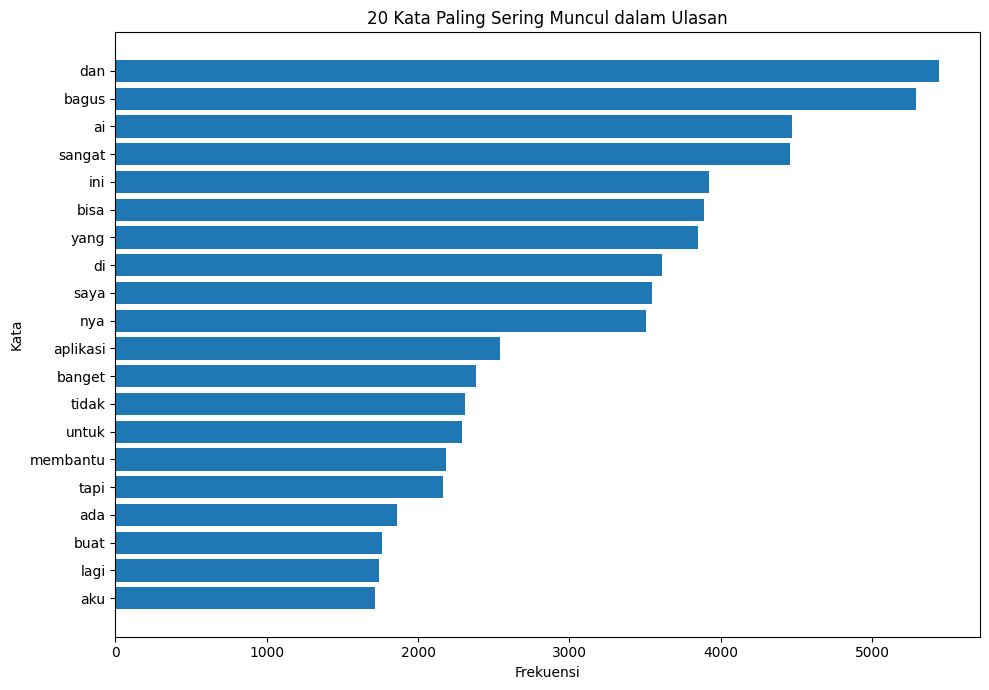

In [13]:
# Visualisasi 20 kata paling sering muncul
top_words = word_freq.most_common(20)

freq_df = pd.DataFrame(
    top_words,
    columns=['kata', 'frekuensi']
)

plt.figure(figsize=(10, 7))

plt.barh(
    freq_df['kata'][::-1],
    freq_df['frekuensi'][::-1]
)

plt.title('20 Kata Paling Sering Muncul dalam Ulasan')
plt.xlabel('Frekuensi')
plt.ylabel('Kata')
plt.tight_layout()
plt.show()

In [14]:
# Melakukan case folding
df['content_case_fold'] = df['content'].str.lower()

df.head()

,content,score,content_case_fold
0,geloo keren bgt ni Ai,5,geloo keren bgt ni ai
1,KENAPASIH RAWAN BANGET BUAT NGE BANNED? AKU UD...,1,kenapasih rawan banget buat nge banned? aku ud...
2,"aku udah langganan individu pro, tapi gak bisa...",3,"aku udah langganan individu pro, tapi gak bisa..."
3,Bagus sih... tapi tolong ya... Jangan terlalu ...,3,bagus sih... tapi tolong ya... jangan terlalu ...
4,data center harus pakai neuro + nano + klorofi...,4,data center harus pakai neuro + nano + klorofi...


In [15]:
# Konversi emoji menjadi teks
def konversi_emoji(teks):
    return emoji.demojize(teks, language='id')

df['content_emoji'] = (
    df['content_case_fold']
    .fillna('')
    .astype(str)
    .apply(konversi_emoji)
)

df.head()

,content,score,content_case_fold,content_emoji
0,geloo keren bgt ni Ai,5,geloo keren bgt ni ai,geloo keren bgt ni ai
1,KENAPASIH RAWAN BANGET BUAT NGE BANNED? AKU UD...,1,kenapasih rawan banget buat nge banned? aku ud...,kenapasih rawan banget buat nge banned? aku ud...
2,"aku udah langganan individu pro, tapi gak bisa...",3,"aku udah langganan individu pro, tapi gak bisa...","aku udah langganan individu pro, tapi gak bisa..."
3,Bagus sih... tapi tolong ya... Jangan terlalu ...,3,bagus sih... tapi tolong ya... jangan terlalu ...,bagus sih... tapi tolong ya... jangan terlalu ...
4,data center harus pakai neuro + nano + klorofi...,4,data center harus pakai neuro + nano + klorofi...,data center harus pakai neuro + nano + klorofi...


In [16]:
# Cleaning teks
text = df['content_emoji'].fillna('').astype(str)

text = text.str.replace(r'https?://\S+|www\.\S+', '', regex=True)
text = text.str.replace(r'<[^>]+>', '', regex=True)
text = text.str.replace(r'@\w+', '', regex=True)
text = text.str.replace(r'#(\w+)', r'\1', regex=True)
text = text.str.replace(r'[\U0001F300-\U0001FAFF]', '', regex=True)
text = text.str.replace(r'\d+', '', regex=True)
text = text.str.replace(r'[^\w\s]', ' ', regex=True)
text = text.str.replace('_', ' ', regex=False)
text = text.str.replace(r'\s+', ' ', regex=True).str.strip()

df['content_clean'] = text

df.head()

,content,score,content_case_fold,content_emoji,content_clean
0,geloo keren bgt ni Ai,5,geloo keren bgt ni ai,geloo keren bgt ni ai,geloo keren bgt ni ai
1,KENAPASIH RAWAN BANGET BUAT NGE BANNED? AKU UD...,1,kenapasih rawan banget buat nge banned? aku ud...,kenapasih rawan banget buat nge banned? aku ud...,kenapasih rawan banget buat nge banned aku uda...
2,"aku udah langganan individu pro, tapi gak bisa...",3,"aku udah langganan individu pro, tapi gak bisa...","aku udah langganan individu pro, tapi gak bisa...",aku udah langganan individu pro tapi gak bisa ...
3,Bagus sih... tapi tolong ya... Jangan terlalu ...,3,bagus sih... tapi tolong ya... jangan terlalu ...,bagus sih... tapi tolong ya... jangan terlalu ...,bagus sih tapi tolong ya jangan terlalu lama w...
4,data center harus pakai neuro + nano + klorofi...,4,data center harus pakai neuro + nano + klorofi...,data center harus pakai neuro + nano + klorofi...,data center harus pakai neuro nano klorofil te...


In [17]:
# normalisasi kata
kamus = pd.read_excel('kamuskatabaku.xlsx')

kamus.head()

,tidak_baku,kata_baku
0,woww,wow
1,aminn,amin
2,met,selamat
3,netaas,menetas
4,keberpa,keberapa


In [18]:
slang_dict = dict(zip(kamus['tidak_baku'], kamus['kata_baku']))

def normalisasi_kata(teks):
    teks_split = teks.split()
    kata_kata = []
    for iter in teks_split:
        kata = slang_dict.get(iter, iter)
        kata_kata.append(kata)
    return ' '.join(kata_kata)

df['content_normalized'] = df['content_clean'].apply(normalisasi_kata)

df.head()

,content,score,content_case_fold,content_emoji,content_clean,content_normalized
0,geloo keren bgt ni Ai,5,geloo keren bgt ni ai,geloo keren bgt ni ai,geloo keren bgt ni ai,geloo keren banget nih ai
1,KENAPASIH RAWAN BANGET BUAT NGE BANNED? AKU UD...,1,kenapasih rawan banget buat nge banned? aku ud...,kenapasih rawan banget buat nge banned? aku ud...,kenapasih rawan banget buat nge banned aku uda...,kenapasih rawan banget buat nge banned aku sud...
2,"aku udah langganan individu pro, tapi gak bisa...",3,"aku udah langganan individu pro, tapi gak bisa...","aku udah langganan individu pro, tapi gak bisa...",aku udah langganan individu pro tapi gak bisa ...,aku sudah langganan individu pro tapi tidak bi...
3,Bagus sih... tapi tolong ya... Jangan terlalu ...,3,bagus sih... tapi tolong ya... jangan terlalu ...,bagus sih... tapi tolong ya... jangan terlalu ...,bagus sih tapi tolong ya jangan terlalu lama w...,bagus sih tapi tolong ya jangan terlalu lama w...
4,data center harus pakai neuro + nano + klorofi...,4,data center harus pakai neuro + nano + klorofi...,data center harus pakai neuro + nano + klorofi...,data center harus pakai neuro nano klorofil te...,data center harus pakai neuro nano klorofil te...


In [20]:
# Mendeteksi bahasa yang digunakan
DetectorFactory.seed = 42

def detect_language(text):
    if not isinstance(text, str) or not text.strip():
        return 'kosong'

    try:
        return detect(text)
    except LangDetectException:
        return 'tidak_terdeteksi'

print(df['content_normalized'].apply(detect_language).value_counts())

content_normalized
id                  19901
en                   1403
tl                   1172
so                    269
fi                    238
da                    199
af                    189
no                    183
et                    152
sw                    141
sl                    133
hr                    129
it                    113
lt                    107
ro                    101
cy                    100
ca                     76
nl                     75
pl                     74
hu                     68
sk                     62
fr                     58
tidak_terdeteksi       47
tr                     39
sq                     35
sv                     34
es                     33
pt                     32
de                     26
lv                     25
cs                     15
zh-cn                  10
kosong                  9
ja                      6
ar                      4
ko                      4
vi                      3
he                 

In [21]:
# Stopword removal
stop_words = set(stopwords.words('indonesian') + stopwords.words('english'))

# Mempertahankan kata negasi
stop_words -= {'tidak', 'bukan', 'belum', 'jangan', 'sangat'}

df['content_no_stopword'] = df['content_normalized'].apply(
    lambda teks: ' '.join(
        word for word in teks.split()
        if word not in stop_words
    )
)

df.head()

,content,score,content_case_fold,content_emoji,content_clean,content_normalized,content_no_stopword
0,geloo keren bgt ni Ai,5,geloo keren bgt ni ai,geloo keren bgt ni ai,geloo keren bgt ni ai,geloo keren banget nih ai,geloo keren banget nih ai
1,KENAPASIH RAWAN BANGET BUAT NGE BANNED? AKU UD...,1,kenapasih rawan banget buat nge banned? aku ud...,kenapasih rawan banget buat nge banned? aku ud...,kenapasih rawan banget buat nge banned aku uda...,kenapasih rawan banget buat nge banned aku sud...,kenapasih rawan banget nge banned umur legal c...
2,"aku udah langganan individu pro, tapi gak bisa...",3,"aku udah langganan individu pro, tapi gak bisa...","aku udah langganan individu pro, tapi gak bisa...",aku udah langganan individu pro tapi gak bisa ...,aku sudah langganan individu pro tapi tidak bi...,langganan individu pro tidak verifikasi kadalu...
3,Bagus sih... tapi tolong ya... Jangan terlalu ...,3,bagus sih... tapi tolong ya... jangan terlalu ...,bagus sih... tapi tolong ya... jangan terlalu ...,bagus sih tapi tolong ya jangan terlalu lama w...,bagus sih tapi tolong ya jangan terlalu lama w...,bagus sih tolong ya jangan reset ya berhenti j...
4,data center harus pakai neuro + nano + klorofi...,4,data center harus pakai neuro + nano + klorofi...,data center harus pakai neuro + nano + klorofi...,data center harus pakai neuro nano klorofil te...,data center harus pakai neuro nano klorofil te...,data center pakai neuro nano klorofil tech ram...


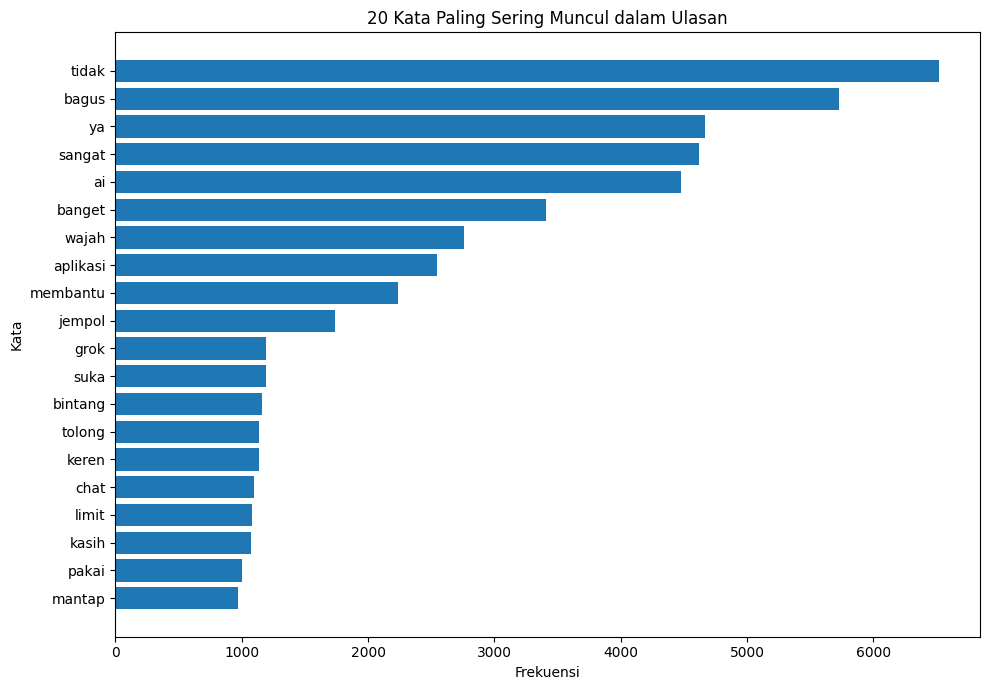

In [22]:
# Menghitung frekuensi kata setelah cleaning
texts = df['content_no_stopword'].dropna().astype(str)
all_text = ' '.join(texts)
words = re.findall(r'\b\w+\b', all_text.lower())

word_freq = Counter(words)

top_words = word_freq.most_common(20)

freq_df = pd.DataFrame(
    top_words,
    columns=['kata', 'frekuensi']
)

plt.figure(figsize=(10, 7))

plt.barh(
    freq_df['kata'][::-1],
    freq_df['frekuensi'][::-1]
)

plt.title('20 Kata Paling Sering Muncul dalam Ulasan')
plt.xlabel('Frekuensi')
plt.ylabel('Kata')
plt.tight_layout()
plt.show()

In [23]:
# melihat 200 kata teratas
top_words = word_freq.most_common(200)

freq_df = pd.DataFrame(
    top_words,
    columns=['kata', 'frekuensi']
)

top_words_list = [word for word, freq in top_words]

print(top_words_list)

['tidak', 'bagus', 'ya', 'sangat', 'ai', 'banget', 'wajah', 'aplikasi', 'membantu', 'jempol', 'grok', 'suka', 'bintang', 'tolong', 'keren', 'chat', 'limit', 'kasih', 'pakai', 'mantap', 'gambar', 'sih', 'gratis', 'hati', 'gemini', 'foto', 'mata', 'bikin', 'tangan', 'fitur', 'apk', 'tersenyum', 'gue', 'cepat', 'server', 'kayak', 'deepseek', 'good', 'chatgpt', 'update', 'video', 'berbayar', 'jangan', 'bayar', 'mahal', 'kali', 'kadang', 'gpt', 'sesuai', 'mudah', 'edit', 'orang', 'claude', 'coba', 'melipat', 'free', 'nih', 'jelek', 'terima', 'gembira', 'semoga', 'akun', 'perbaiki', 'warna', 'belajar', 'ku', 'kulit', 'tugas', 'belum', 'cerah', 'aplikasinya', 'putih', 'pas', 'error', 'terbaik', 'best', 'langsung', 'bahasa', 'pesan', 'keras', 'pengguna', 'terimakasih', 'menangis', 'google', 'salah', 'berguna', 'kena', 'mengobrol', 'app', 'respon', 'air', 'tau', 'hasil', 'oke', 'busy', 'medium', 'bug', 'lebar', 'batas', 'gua', 'lumayan', 'cuman', 'pokoknya', 'premium', 'langganan', 'login', 'di

In [24]:
# Hapus kata yang sering muncul namun kurang relevan setelah di cleaning
hapus_kata = [
    'ya',
    'aplikasi',
    'apk',
    'ai',
    'aplikasinya',
    'app',
    'sih',
    'nih',
    'deh',
    'sok',
    'ku',
    'nya',
    'orang',
    'jam',
    'sehari',
    'air',
    'tangan',
    'mata',
    'jari',
    'warna',
    'kulit',
    'merah',
    'putih',
    'wajah',
    'tersenyum',
    'melipat',
    'berurai',
    'bersinar',
    'moai',
    'rudy'
]

df['content_no_stopword'] = df['content_no_stopword'].apply(
    lambda x: ' '.join(
        kata for kata in x.split()
        if kata not in hapus_kata
    )
)

In [25]:
# Mengecek null value & duplicate setelah cleaning
print(df['content_no_stopword'].isnull().sum())
print(df['content_no_stopword'].duplicated().sum())

0
4021


In [26]:
# Menghapus duplicate
df.drop_duplicates(subset=['content_no_stopword'], inplace=True)

print(df['content_no_stopword'].duplicated().sum())
df.info()

0
<class 'pandas.core.frame.DataFrame'>
Index: 21249 entries, 0 to 38781
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   content              21249 non-null  object
 1   score                21249 non-null  int64 
 2   content_case_fold    21249 non-null  object
 3   content_emoji        21249 non-null  object
 4   content_clean        21249 non-null  object
 5   content_normalized   21249 non-null  object
 6   content_no_stopword  21249 non-null  object
dtypes: int64(1), object(6)
memory usage: 1.3+ MB


# **Labeling Data dengan Lexicon & Melakukan Encoding**

In [27]:
# Mengambil data bersih
df_cleaned = df.copy()

df_cleaned.head()

,content,score,content_case_fold,content_emoji,content_clean,content_normalized,content_no_stopword
0,geloo keren bgt ni Ai,5,geloo keren bgt ni ai,geloo keren bgt ni ai,geloo keren bgt ni ai,geloo keren banget nih ai,geloo keren banget
1,KENAPASIH RAWAN BANGET BUAT NGE BANNED? AKU UD...,1,kenapasih rawan banget buat nge banned? aku ud...,kenapasih rawan banget buat nge banned? aku ud...,kenapasih rawan banget buat nge banned aku uda...,kenapasih rawan banget buat nge banned aku sud...,kenapasih rawan banget nge banned umur legal c...
2,"aku udah langganan individu pro, tapi gak bisa...",3,"aku udah langganan individu pro, tapi gak bisa...","aku udah langganan individu pro, tapi gak bisa...",aku udah langganan individu pro tapi gak bisa ...,aku sudah langganan individu pro tapi tidak bi...,langganan individu pro tidak verifikasi kadalu...
3,Bagus sih... tapi tolong ya... Jangan terlalu ...,3,bagus sih... tapi tolong ya... jangan terlalu ...,bagus sih... tapi tolong ya... jangan terlalu ...,bagus sih tapi tolong ya jangan terlalu lama w...,bagus sih tapi tolong ya jangan terlalu lama w...,bagus tolong jangan reset berhenti siang dires...
4,data center harus pakai neuro + nano + klorofi...,4,data center harus pakai neuro + nano + klorofi...,data center harus pakai neuro + nano + klorofi...,data center harus pakai neuro nano klorofil te...,data center harus pakai neuro nano klorofil te...,data center pakai neuro nano klorofil tech ram...


In [28]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21249 entries, 0 to 38781
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   content              21249 non-null  object
 1   score                21249 non-null  int64 
 2   content_case_fold    21249 non-null  object
 3   content_emoji        21249 non-null  object
 4   content_clean        21249 non-null  object
 5   content_normalized   21249 non-null  object
 6   content_no_stopword  21249 non-null  object
dtypes: int64(1), object(6)
memory usage: 1.3+ MB


In [29]:
# Mengecek top words sebelum labeling
top_words = [word for word, freq in word_freq.most_common(200)]

print(top_words)

['tidak', 'bagus', 'ya', 'sangat', 'ai', 'banget', 'wajah', 'aplikasi', 'membantu', 'jempol', 'grok', 'suka', 'bintang', 'tolong', 'keren', 'chat', 'limit', 'kasih', 'pakai', 'mantap', 'gambar', 'sih', 'gratis', 'hati', 'gemini', 'foto', 'mata', 'bikin', 'tangan', 'fitur', 'apk', 'tersenyum', 'gue', 'cepat', 'server', 'kayak', 'deepseek', 'good', 'chatgpt', 'update', 'video', 'berbayar', 'jangan', 'bayar', 'mahal', 'kali', 'kadang', 'gpt', 'sesuai', 'mudah', 'edit', 'orang', 'claude', 'coba', 'melipat', 'free', 'nih', 'jelek', 'terima', 'gembira', 'semoga', 'akun', 'perbaiki', 'warna', 'belajar', 'ku', 'kulit', 'tugas', 'belum', 'cerah', 'aplikasinya', 'putih', 'pas', 'error', 'terbaik', 'best', 'langsung', 'bahasa', 'pesan', 'keras', 'pengguna', 'terimakasih', 'menangis', 'google', 'salah', 'berguna', 'kena', 'mengobrol', 'app', 'respon', 'air', 'tau', 'hasil', 'oke', 'busy', 'medium', 'bug', 'lebar', 'batas', 'gua', 'lumayan', 'cuman', 'pokoknya', 'premium', 'langganan', 'login', 'di

In [30]:
# Labeling dengan lexicon
lexicon_sentimen = SentimentIntensityAnalyzer()

# Rules tertentu untuk labeling
set_value = {
    # Positif kuat
    'unggul': 2.5,
    'bagus': 2.5,
    'keren': 2.5,
    'mantap': 2.5,
    'terbaik': 3.0,
    'mantul': 2.5,
    'memuaskan': 2.5,
    'berguna': 2.0,
    'bermanfaat': 2.0,
    'membantu': 2.0,
    'akurat': 2.0,
    'puas': 2.5,
    'suka': 2.0,
    'gembira': 2.5,
    'bahagia': 2.5,
    'cerah': 1.5,
    'mudah': 1.5,
    'cepat': 1.5,
    'good': 2.0,
    'best': 2.5,
    'nice': 2.0,
    'love': 3.0,
    'enak': 1.5,
    'asik': 2.0,
    'seru': 2.0,
    'terimakasih': 1.5,
    'terima': 0.5,
    'like': 1.5,
    'jempol': 2.0,

    # Negatif kuat
    'buruk': -2.5,
    'jelek': -2.5,
    'kecewa': -3.0,
    'parah': -2.0,
    'error': -2.0,
    'eror': -2.0,
    'bug': -2.0,
    'susah': -2.0,
    'mahal': -2.0,
    'pelit': -2.0,
    'kikir': -2.0,
    'tolol': -3.0,
    'aneh': -1.5,
    'salah': -2.0,
    'gila': -1.0,
    'sampah': -3.0,
    'hilang': -1.5,
    'kesalahan': -2.0,
    'marah': -2.0,
    'menangis': -1.5,
    'tolong': -2.0,
    'payah': -2.0,
    'lambat': -2.0,
    'lemot': -2.5,
    'kecewa banget': -3.5,
    'jelek banget': -3.0,
    'kurang': -2.5,
    'aneh': -2.5
}

lexicon_sentimen.lexicon.update(set_value)

# Fungsi untuk menghitung skor sentimen
def hitung_sentimen(teks):
    if not isinstance(teks, str) or not teks.strip():
        return 0.0

    skor = lexicon_sentimen.polarity_scores(teks.lower())
    return skor['compound']

In [31]:
# Labeling
def buat_label(skor):
    if skor >= 0.05:
        return 'positif'
    elif skor <= -0.05:
        return 'negatif'
    else:
        return 'netral'

df_cleaned['sentiment_score'] = df_cleaned['content_no_stopword'].apply(hitung_sentimen)
df_cleaned['label'] = df_cleaned['sentiment_score'].apply(buat_label)

print(df_cleaned['label'].value_counts())
df_cleaned.head()


label
positif    11171
netral      6727
negatif     3351
Name: count, dtype: int64


,content,score,content_case_fold,content_emoji,content_clean,content_normalized,content_no_stopword,sentiment_score,label
0,geloo keren bgt ni Ai,5,geloo keren bgt ni ai,geloo keren bgt ni ai,geloo keren bgt ni ai,geloo keren banget nih ai,geloo keren banget,0.5423,positif
1,KENAPASIH RAWAN BANGET BUAT NGE BANNED? AKU UD...,1,kenapasih rawan banget buat nge banned? aku ud...,kenapasih rawan banget buat nge banned? aku ud...,kenapasih rawan banget buat nge banned aku uda...,kenapasih rawan banget buat nge banned aku sud...,kenapasih rawan banget nge banned umur legal c...,-0.8126,negatif
2,"aku udah langganan individu pro, tapi gak bisa...",3,"aku udah langganan individu pro, tapi gak bisa...","aku udah langganan individu pro, tapi gak bisa...",aku udah langganan individu pro tapi gak bisa ...,aku sudah langganan individu pro tapi tidak bi...,langganan individu pro tidak verifikasi kadalu...,0.0000,netral
3,Bagus sih... tapi tolong ya... Jangan terlalu ...,3,bagus sih... tapi tolong ya... jangan terlalu ...,bagus sih... tapi tolong ya... jangan terlalu ...,bagus sih tapi tolong ya jangan terlalu lama w...,bagus sih tapi tolong ya jangan terlalu lama w...,bagus tolong jangan reset berhenti siang dires...,-0.3612,negatif
4,data center harus pakai neuro + nano + klorofi...,4,data center harus pakai neuro + nano + klorofi...,data center harus pakai neuro + nano + klorofi...,data center harus pakai neuro nano klorofil te...,data center harus pakai neuro nano klorofil te...,data center pakai neuro nano klorofil tech ram...,-0.8402,negatif


In [32]:
# Hapus kolom yang tidak di perlukan
hapus_kolom = ['content_case_fold', 'content_emoji', 'content_clean', 'content_normalized', 'sentiment_score']

df_cleaned.drop(columns=hapus_kolom, inplace=True)

In [33]:
df_cleaned.head()

,content,score,content_no_stopword,label
0,geloo keren bgt ni Ai,5,geloo keren banget,positif
1,KENAPASIH RAWAN BANGET BUAT NGE BANNED? AKU UD...,1,kenapasih rawan banget nge banned umur legal c...,negatif
2,"aku udah langganan individu pro, tapi gak bisa...",3,langganan individu pro tidak verifikasi kadalu...,netral
3,Bagus sih... tapi tolong ya... Jangan terlalu ...,3,bagus tolong jangan reset berhenti siang dires...,negatif
4,data center harus pakai neuro + nano + klorofi...,4,data center pakai neuro nano klorofil tech ram...,negatif


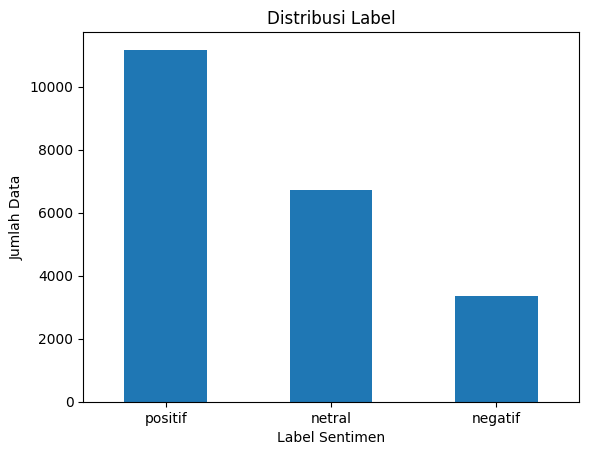

In [34]:
# Visualisasi distribusi label
df_cleaned['label'].value_counts().plot(kind='bar')

plt.title('Distribusi Label')
plt.xlabel('Label Sentimen')
plt.ylabel('Jumlah Data')
plt.xticks(rotation=0)
plt.show()

In [35]:
# Encoding label
df_cleaned['label'] = df_cleaned['label'].map({
    'negatif': 0,
    'netral': 1,
    'positif': 2
})

df_cleaned.head()

,content,score,content_no_stopword,label
0,geloo keren bgt ni Ai,5,geloo keren banget,2
1,KENAPASIH RAWAN BANGET BUAT NGE BANNED? AKU UD...,1,kenapasih rawan banget nge banned umur legal c...,0
2,"aku udah langganan individu pro, tapi gak bisa...",3,langganan individu pro tidak verifikasi kadalu...,1
3,Bagus sih... tapi tolong ya... Jangan terlalu ...,3,bagus tolong jangan reset berhenti siang dires...,0
4,data center harus pakai neuro + nano + klorofi...,4,data center pakai neuro nano klorofil tech ram...,0


# **Skema 1: Pelatihan: SVM, Ekstraksi Fitur: TF-IDF, Pembagian Data: 80/20**

## Membuat variable baru & cek distribusi

In [64]:
df_svm = df_cleaned.copy()

print("\nDistribusi label:")
print(df_svm['label'].value_counts().sort_index())


Distribusi label:
label
0     3351
1     6727
2    11171
Name: count, dtype: int64


## Splitting data 80/20

In [65]:
X = df_svm['content_no_stopword']
y = df_svm['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

Jumlah data training: 16999
Jumlah data testing: 4250


## Feature Extraction dengan TF-IDF

In [66]:
svm_tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_train_tfidf = svm_tfidf.fit_transform(X_train)

X_test_tfidf = svm_tfidf.transform(X_test)

print("Bentuk matriks training:", X_train_tfidf.shape)
print("Bentuk matriks testing:", X_test_tfidf.shape)
print("Jumlah fitur TF-IDF:", len(svm_tfidf.get_feature_names_out()))

Bentuk matriks training: (16999, 10000)
Bentuk matriks testing: (4250, 10000)
Jumlah fitur TF-IDF: 10000


## Menangani imbalance dengan oversampling

In [67]:
print("Before oversampling:")
print(Counter(y_train))

ros = RandomOverSampler(random_state=42)
X_train_resampled, y_train_resampled = ros.fit_resample(X_train_tfidf, y_train)

print("\nAfter oversampling:")
print(Counter(y_train_resampled))

print("\nTest data distribution (unchanged):")
print(Counter(y_test))


Before oversampling:
Counter({2: 8937, 1: 5381, 0: 2681})

After oversampling:
Counter({1: 8937, 0: 8937, 2: 8937})

Test data distribution (unchanged):
Counter({2: 2234, 1: 1346, 0: 670})


## Training Model dengan SVM

In [68]:
svm_model = LinearSVC(random_state=42)
svm_model.fit(X_train_resampled, y_train_resampled)

,penalty,'l2'
,loss,'squared_hinge'
,dual,'auto'
,tol,0.0001
,C,1.0
,multi_class,'ovr'
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,verbose,0
,random_state,42


## Evaluasi model

In [71]:
y_train_pred = svm_model.predict(X_train_resampled)
y_test_pred = svm_model.predict(X_test_tfidf)

print("=== HASIL EVALUASI SVM ===")
print(f"Training Accuracy : {accuracy_score(y_train_resampled, y_train_pred):.2f} ({accuracy_score(y_train_resampled, y_train_pred) * 100:.2f}%)")
print(f"Testing Accuracy  : {accuracy_score(y_test, y_test_pred):.2f} ({accuracy_score(y_test, y_test_pred) * 100:.2f}%)")

print("\n=== CLASSIFICATION REPORT (TESTING) ===")
print(classification_report(y_test, y_test_pred))

=== HASIL EVALUASI SVM ===
Training Accuracy : 1.00 (99.53%)
Testing Accuracy  : 0.95 (95.34%)

=== CLASSIFICATION REPORT (TESTING) ===
              precision    recall  f1-score   support

           0       0.92      0.91      0.92       670
           1       0.93      0.97      0.95      1346
           2       0.98      0.96      0.97      2234

    accuracy                           0.95      4250
   macro avg       0.94      0.95      0.94      4250
weighted avg       0.95      0.95      0.95      4250



## Evaluasi dengan Confusion Matrix

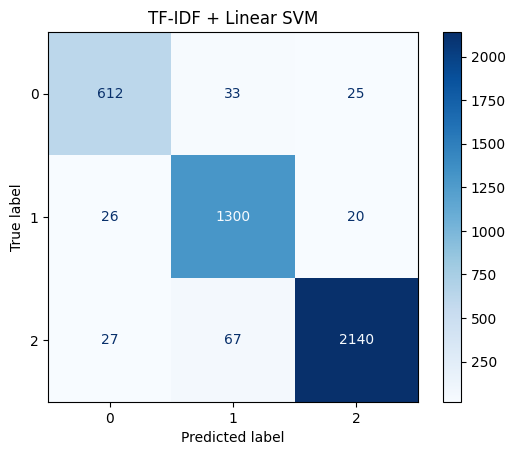

In [72]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    cmap="Blues"
)

plt.title("TF-IDF + Linear SVM")
plt.show()

## Menyimpan Model

In [73]:
joblib.dump(svm_model, 'svm_model.pkl')
joblib.dump(svm_tfidf, 'svm_tfidf.pkl')

['svm_tfidf.pkl']

# **Skema 2: Pelatihan: Random Forest, Ekstraksi Fitur: TF-IDF, Pembagian Data: 70/30**

## Membuat variable baru & cek distribusi

In [74]:
df_rf = df_cleaned.copy()

print("\nDistribusi label:")
print(df_rf['label'].value_counts().sort_index())


Distribusi label:
label
0     3351
1     6727
2    11171
Name: count, dtype: int64


## Splitting data 70/20

In [75]:
X = df_rf['content_no_stopword']
y = df_rf['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

Jumlah data training: 14874
Jumlah data testing: 6375


## Feature Extraction dengan TF-IDF

In [76]:
rf_tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_train_tfidf = rf_tfidf.fit_transform(X_train)

X_test_tfidf = rf_tfidf.transform(X_test)

print("Bentuk matriks training:", X_train_tfidf.shape)
print("Bentuk matriks testing:", X_test_tfidf.shape)
print("Jumlah fitur TF-IDF:", len(rf_tfidf.get_feature_names_out()))

Bentuk matriks training: (14874, 10000)
Bentuk matriks testing: (6375, 10000)
Jumlah fitur TF-IDF: 10000


## Training model RF

In [77]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=100,
    min_samples_split=2,
    class_weight=None,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_tfidf, y_train)

,n_estimators,200
,criterion,'gini'
,max_depth,100
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


## Evaluasi model RF

In [78]:
y_train_pred = rf_model.predict(X_train_tfidf)
y_test_pred = rf_model.predict(X_test_tfidf)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print("=== HASIL EVALUASI RANDOM FOREST ===")
print(f"Training Accuracy : {train_accuracy:.2f} ({train_accuracy * 100:.2f}%)")
print(f"Testing Accuracy  : {test_accuracy:.2f} ({test_accuracy * 100:.2f}%)")

print("\nClassification Report (Testing):")
print(classification_report(
    y_test,
    y_test_pred,
    zero_division=0
))

=== HASIL EVALUASI RANDOM FOREST ===
Training Accuracy : 0.98 (98.07%)
Testing Accuracy  : 0.93 (93.47%)

Classification Report (Testing):
              precision    recall  f1-score   support

           0       0.95      0.80      0.87      1005
           1       0.89      0.97      0.93      2018
           2       0.96      0.95      0.96      3352

    accuracy                           0.93      6375
   macro avg       0.93      0.91      0.92      6375
weighted avg       0.94      0.93      0.93      6375



## Evaluasi dengan Confusion Matrix

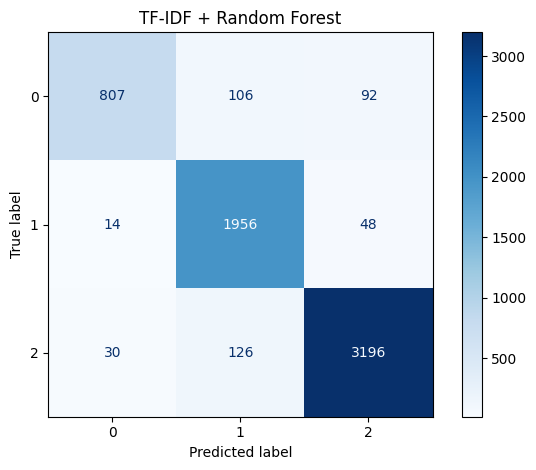

In [79]:
# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    cmap="Blues"
)

plt.title("TF-IDF + Random Forest")
plt.tight_layout()
plt.show()

## Menyimpan model RF

In [80]:
joblib.dump(rf_model, "rf_model.pkl")
joblib.dump(rf_tfidf, 'rf_tfidf.pkl')

['rf_tfidf.pkl']

# **Skema 3: BiGRU, Pembagian Data: 70/15/15**

## Set random SEED

In [81]:
SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)

## Membuat variable baru & cek data

In [82]:
df_bigru = df_cleaned.copy()

df_bigru.head()

,content,score,content_no_stopword,label
0,geloo keren bgt ni Ai,5,geloo keren banget,2
1,KENAPASIH RAWAN BANGET BUAT NGE BANNED? AKU UD...,1,kenapasih rawan banget nge banned umur legal c...,0
2,"aku udah langganan individu pro, tapi gak bisa...",3,langganan individu pro tidak verifikasi kadalu...,1
3,Bagus sih... tapi tolong ya... Jangan terlalu ...,3,bagus tolong jangan reset berhenti siang dires...,0
4,data center harus pakai neuro + nano + klorofi...,4,data center pakai neuro nano klorofil tech ram...,0


## Cek distribusi label

In [83]:
X = df_bigru['content_no_stopword']
y = df_bigru['label']

print("Jumlah data:", len(df_bigru))
print("\nDistribusi label:")
print(y.value_counts())

Jumlah data: 21249

Distribusi label:
label
2    11171
1     6727
0     3351
Name: count, dtype: int64


## Splitting 70/15/15

In [84]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=SEED, stratify=y)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp)

print("Training  :", len(X_train))
print("Validation:", len(X_val))
print("Testing   :", len(X_test))

Training  : 14874
Validation: 3187
Testing   : 3188


## Tokenisasi & Padding

In [85]:
MAX_WORDS = 30000

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token='<OOV>'
)

tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

lengths = [len(seq) for seq in X_train_seq]
MAX_LEN = max(1, int(__import__('numpy').percentile(lengths, 95)))

X_train_pad = pad_sequences(
    X_train_seq, maxlen=MAX_LEN,
    padding='post', truncating='post'
)

X_val_pad = pad_sequences(
    X_val_seq, maxlen=MAX_LEN,
    padding='post', truncating='post'
)

X_test_pad = pad_sequences(
    X_test_seq, maxlen=MAX_LEN,
    padding='post', truncating='post'
)

vocab_size = min(
    MAX_WORDS,
    len(tokenizer.word_index) + 1
)

## Build & Training BiGRU

In [86]:
tf.random.set_seed(SEED)

model = Sequential([
    Input(shape=(MAX_LEN,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=128,
        mask_zero=True
    ),

    Bidirectional(GRU(64)),
    Dropout(0.4),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(3, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history = model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=10,
    batch_size=64,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/10
233/233 ━━━━━━━━━━━━━━━━━━━━ 26s 77ms/step - accuracy: 0.8273 - loss: 0.4339 - val_accuracy: 0.9382 - val_loss: 0.2021 - learning_rate: 0.0010
Epoch 2/10
233/233 ━━━━━━━━━━━━━━━━━━━━ 15s 64ms/step - accuracy: 0.9692 - loss: 0.0960 - val_accuracy: 0.9511 - val_loss: 0.1940 - learning_rate: 0.0010
Epoch 3/10
233/233 ━━━━━━━━━━━━━━━━━━━━ 34s 146ms/step - accuracy: 0.9858 - loss: 0.0447 - val_accuracy: 0.9470 - val_loss: 0.2333 - learning_rate: 0.0010
Epoch 4/10
233/233 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9877 - loss: 0.0346
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
233/233 ━━━━━━━━━━━━━━━━━━━━ 20s 85ms/step - accuracy: 0.9890 - loss: 0.0340 - val_accuracy: 0.9554 - val_loss: 0.2158 - learning_rate: 0.0010
Epoch 5/10
233/233 ━━━━━━━━━━━━━━━━━━━━ 15s 64ms/step - accuracy: 0.9925 - loss: 0.0230 - val_accuracy: 0.9514 - val_loss: 0.2200 - learning_rate: 5.0000e-04
Epoch 5: early stopping
Restoring model weights from the end of the best 

## Evaluasi Model BiGRU

In [88]:
y_train_pred_prob = model.predict(X_train_pad, verbose=0)
y_train_pred = np.argmax(y_train_pred_prob, axis=1)

y_test_pred_prob = model.predict(X_test_pad, verbose=0)
y_test_pred = np.argmax(y_test_pred_prob, axis=1)

y_train_true = np.asarray(y_train, dtype=int)
y_test_true = np.asarray(y_test, dtype=int)

train_accuracy = accuracy_score(y_train_true, y_train_pred)
test_accuracy = accuracy_score(y_test_true, y_test_pred)

precision = precision_score(
    y_test_true,
    y_test_pred,
    average='macro',
    zero_division=0
)

recall = recall_score(
    y_test_true,
    y_test_pred,
    average='macro',
    zero_division=0
)

f1 = f1_score(
    y_test_true,
    y_test_pred,
    average='macro',
    zero_division=0
)

print("=== HASIL EVALUASI MODEL BiGRU ===")
print(f"Training Accuracy : {train_accuracy:.2f} ({train_accuracy * 100:.2f}%)")
print(f"Testing Accuracy  : {test_accuracy:.2f} ({test_accuracy * 100:.2f}%)")
print(f"Precision (Macro) : {precision:.4f}")
print(f"Recall (Macro)    : {recall:.4f}")
print(f"F1-Score (Macro)  : {f1:.4f}")

=== HASIL EVALUASI MODEL BiGRU ===
Training Accuracy : 0.99 (98.53%)
Testing Accuracy  : 0.95 (95.48%)
Precision (Macro) : 0.9385
Recall (Macro)    : 0.9498
F1-Score (Macro)  : 0.9439


## Evaluasi klasifikasi BiGRU

In [89]:
print("=== CLASSIFICATION REPORT ===")

print(
    classification_report(
        y_test_true,
        y_test_pred,
        labels=[0, 1, 2],
        target_names=['Negatif', 'Netral', 'Positif'],
        digits=4,
        zero_division=0
    )
)

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

     Negatif     0.8870    0.9364    0.9110       503
      Netral     0.9466    0.9495    0.9480      1009
     Positif     0.9818    0.9636    0.9726      1676

    accuracy                         0.9548      3188
   macro avg     0.9385    0.9498    0.9439      3188
weighted avg     0.9557    0.9548    0.9551      3188



## Evaluasi dengan Confusion Matrix

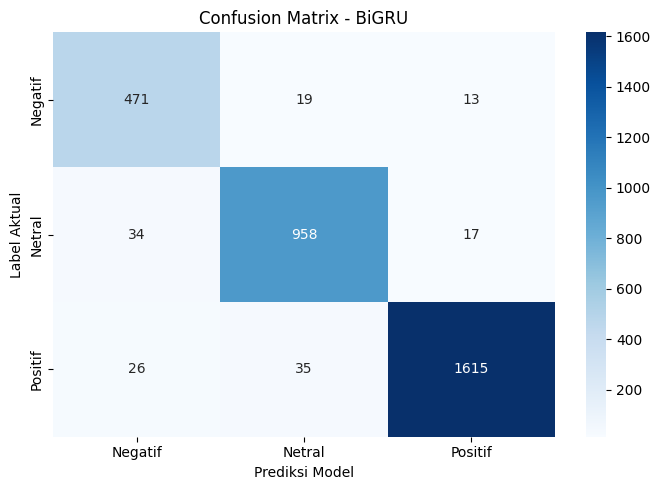

In [90]:
cm = confusion_matrix(
    y_test_true,
    y_test_pred,
    labels=[0, 1, 2]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negatif', 'Netral', 'Positif'],
    yticklabels=['Negatif', 'Netral', 'Positif']
)

plt.title('Confusion Matrix - BiGRU')
plt.xlabel('Prediksi Model')
plt.ylabel('Label Aktual')
plt.tight_layout()
plt.show()


## Menyimpan model dan tokenizer BiGRU

In [91]:
model.save('bigru_model.keras')
with open('bigru_tokenizer.pkl', 'wb') as f:
    pickle.dump(tokenizer, f)

# **Inference (Testing)**

In [92]:
label_mapping = {
    0: "Negatif",
    1: "Netral",
    2: "Positif"
}

def predict_sentiment(text):
    sequence = tokenizer.texts_to_sequences([text])

    padded = pad_sequences(
        sequence,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    probabilities = model.predict(padded, verbose=0)
    predicted_class = int(np.argmax(probabilities, axis=1)[0])

    return label_mapping[predicted_class]


list_reviews = [
    "Aplikasi ini sangat bagus dan mudah digunakan",
    "GPT Bagus banget, gampang dipakai",

    "Lumayanlah ChatGPT",
    "Gemini memiliki fitur yang masuk akal pada umumnya",

    "Claude sangat lemot ga cocok dipake user :(",
    "Aplikasi sering error gajelas",
    "AI jaman batu kah ini? aneh pisan iki"
]

for review in list_reviews:
    hasil = predict_sentiment(review)

    print(f"Review Teks: {review}")
    print(f"Prediksi Sentimen: {hasil}")
    print("=" * 50)


Review Teks: Aplikasi ini sangat bagus dan mudah digunakan
Prediksi Sentimen: Positif
Review Teks: GPT Bagus banget, gampang dipakai
Prediksi Sentimen: Positif
Review Teks: Lumayanlah ChatGPT
Prediksi Sentimen: Netral
Review Teks: Gemini memiliki fitur yang masuk akal pada umumnya
Prediksi Sentimen: Netral
Review Teks: Claude sangat lemot ga cocok dipake user :(
Prediksi Sentimen: Negatif
Review Teks: Aplikasi sering error gajelas
Prediksi Sentimen: Negatif
Review Teks: AI jaman batu kah ini? aneh pisan iki
Prediksi Sentimen: Negatif


# **Freeze Environtment**

In [93]:
%pip freeze requirements.txt

absl-py==2.4.0Note: you may need to restart the kernel to use updated packages.

aiofiles==23.2.1
aiohappyeyeballs==2.6.2
aiohttp==3.13.5
aiosignal==1.4.0
annotated-doc==0.0.4
annotated-types==0.7.0
anyio==4.13.0
ascon==0.0.9
asgiref==3.11.1
asttokens==3.0.2
astunparse==1.6.3
async-timeout==5.0.1
attrs==26.1.0
backoff==2.2.1
bcrypt==5.0.0
beautifulsoup4==4.15.0
blinker==1.9.0
brotli==1.2.0
build==1.5.0
certifi==2026.5.20
cffi==2.0.0
charset-normalizer==3.4.7
chroma-hnswlib==0.7.6
chromadb==0.5.23
click==8.4.1
colorama==0.4.6
coloredlogs==15.0.1
comm==0.2.3
contourpy==1.3.2
cycler==0.12.1
debugpy==1.8.21
decorator==5.3.1
defusedxml==0.7.1
distro==1.9.0
durationpy==0.10
emoji==2.16.0
et_xmlfile==2.0.0
exceptiongroup==1.3.1
executing==2.2.1
fastapi==0.136.3
ffmpy==1.0.0
filelock==3.29.0
Flask==3.1.3
flatbuffers==25.12.19
fonttools==4.63.0
frozenlist==1.8.0
fsspec==2026.3.0
gast==0.7.0
gensim==4.4.0
google-pasta==0.2.0
google-play-scraper==1.2.7
googleapis-common-protos==1.75.0
gradio==5.9